<div style="text-align: center;">
   <font size="5"> 2024年度　数値計算実習　ペア試験問題 </font>
</div>
   <div style="text-align: right;">
   <font size="3"> cc by Shigeto R. Nishitani, 2024/11/21実施 </font>
</div>

- file: ~/symbolic_math/exams_24/24_pair_ans.ipynb
- make problem: pick_works_from_ans 24_pair_ans.ipynb -1 '' '30 31'

以下の問題を python で解き，LUNA へ提出せよ．LUNA へは ipynb と pdf 形式の２種類を提出すること．


# 問１　微積分

## 正規分布(15 点)
次の正規分布関数(ガウス函数)
$$
y = \frac{1}{\sqrt{2\pi\sigma^2} } 
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)
$$
を
$\mu = 3, \sigma =2 $の場合でプロットせよ．

In [1]:
from sympy import *

x = symbols('x')
mu=3
sigma = 2

f=1/sqrt(2*pi*sigma**2)*exp(-(x-mu)**2/(2*sigma**2))

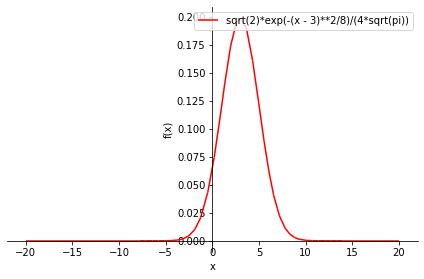

In [2]:
from sympy.plotting import plot
p1 = plot(f, (x,-20,20),
         legend=True, show=False)
p1[0].line_color = 'r'
p1.show()


## ガウス函数の微分(15 点)

全問の関数の1次微分，2次微分を求めて，最大点，変曲点の$x$座標を求めよ．
また，それら関数を同時にプロットせよ．
$\mu, \sigma$の意味を述べよ．

In [3]:
df = diff(f,x)
df

sqrt(2)*(3/4 - x/4)*exp(-(x - 3)**2/8)/(4*sqrt(pi))

In [4]:
d2f = diff(f,x,x)
d2f

sqrt(2)*((x - 3)**2 - 4)*exp(-(x - 3)**2/8)/(64*sqrt(pi))

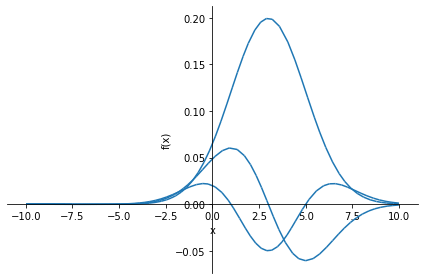

In [5]:
plot(f, df, d2f)

In [6]:
solve(df,x)

[3]

In [7]:
solve(d2f,x)

# muが最大値，mu pm sigmaが変曲点のx座標

[1, 5]

# 問２　線形代数

## グラムシュミット(15 点)

グラム・シュミット法のアルゴリズムは次のとおりである．

入 力 : $n$次元ベクトル$a_1\ldots a_k$

$i=1\ldots k$について
- step1. 直交化: $\tilde{q}_i = a_i -(q_1^{\rm T}a_i)q_1- \cdots - (q_{i-1}^{\rm T}a_i)q_{i-1}. $
- step2. 線形従属かどうかのテスト:$\tilde{q}_i =0$ ならば終了.
- step3. 正規化: $q_i = \tilde{q}_i/|| \tilde{q}_i ||$

以下の$a_1, a_2$に対してグラム・シュミット法を適用し，
正規直交基底を作成せよ．
$$
a_1=\left(
    \begin{array}{@{\,}c@{\,}}
      1 \\
      1 \\
      1 \\
      1 \\
    \end{array}
    \right),~
a_2=\left(
    \begin{array}{@{\,}c@{\,}}
   -2\\
    -1\\
    1 \\
    2
    \end{array}
    \right)
$$

In [3]:
import numpy as np

q_1 = np.array([1,1,1,1])
q_1

array([1, 1, 1, 1])

In [4]:
q1_abs=np.linalg.norm(q_1)
q1_abs

2.0

In [10]:
a_1=1/q1_abs*q_1
a_1

array([0.5, 0.5, 0.5, 0.5])

In [11]:
q_2=np.array([-2,-1,1,2])
q_2_tilde=q_2-(q_2.T*a_1)[0]*a_1
a_2=1/np.linalg.norm(q_2)*q_2
a_2

array([-0.63245553, -0.31622777,  0.31622777,  0.63245553])

## QRDecomposition(15 点)

$$
A=\left(
    \begin{array}{@{\,}c@{\,}c@{\,}}
      1 & -2\\
      1 & -1 \\
      1 & 1 \\
      1 & 2 
    \end{array}
    \right)
$$

に対してQRDecompositionによって直交行列QとR行列を求めよ．

さらに，列ベクトル$y$ 
$$
y=\left(
    \begin{array}{@{\,}c@{\,}}
      -4\\
      -1 \\
      1 \\
      4
    \end{array}
    \right)
$$
に対して$R^{-1}Q^{T}y$ を計算せよ．

得られた解は，４つのデータ[[-2,-4],[-1,-1],[1,1],[2,4]]に対する一次関数$f(x)=a_0+a_1\,x$ による最小2乗近似となる．

In [12]:
AA = np.transpose(np.vstack((q_1,q_2)))
AA

array([[ 1, -2],
       [ 1, -1],
       [ 1,  1],
       [ 1,  2]])

In [13]:
np.linalg.qr(AA)


(array([[-0.5       , -0.63245553],
        [-0.5       , -0.31622777],
        [-0.5       ,  0.31622777],
        [-0.5       ,  0.63245553]]),
 array([[-2.        ,  0.        ],
        [ 0.        ,  3.16227766]]))

In [14]:
yy=np.array([-4,-1,1,4])

In [15]:
Q, R = np.linalg.qr(AA)
pp = np.dot(np.dot(np.linalg.inv(R),np.transpose(Q)),yy)
pp

array([0. , 1.8])

In [43]:
yy

array([-4, -1,  1,  4])

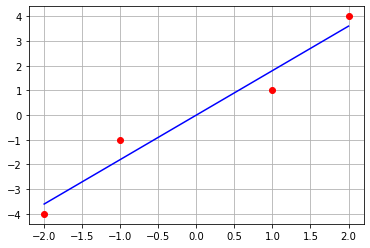

In [44]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def f(x, a0, a1):
    return a0 + a1*x 

xdata = q_2
ydata = yy
plt.plot(xdata,ydata, 'o', color='r')

x =np.linspace(-2,2,20)
y = f(x, pp[0], pp[1])  #,params[2])
plt.plot(x,y, color='b')

plt.grid()
plt.show()

# 問3 センター試験(20 点)

注：$|x|$に対して特殊な関数は適用せず，積分では$x$の範囲で$g1 = g(x), g2 = -g(x)$と2つの関数を用意して考えよ．

2021年度：数学II・B/本試験(第2日程) 第２問[2]


$g(x)=|x|(x+1)$とおく．

点P(-1, 0)を通り，傾きが$c$の直線を$l$とする．
$g'(-1)=\fbox{ サ }$であるから，
$0<c<\fbox{ サ }$のとき，
曲線$y=g(x)$と直線$l$は3点で交わる．
そのうちの1点はPであり，
残りの2点は点Pに近い方から順にQ,Rとすると，
点Qの$x$座標は$\fbox{ シス }$であり，
点Rの$x$座標は$\fbox{ セ }$である．

In [18]:
from sympy import *

c, x = symbols('c x')
g=-x*(x+1)

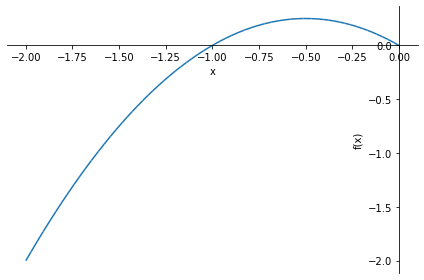

In [19]:
%matplotlib inline

line_1 = g
line_2 = -g
plot(line_1, (x,-2, 0), color='red')

In [20]:
diff(g,x)

-2*x - 1

In [21]:
m= diff(g,x).subs({x:-1})
m

1

In [22]:
l_c=m*(x+1)

In [23]:
#  以下はc=0.5のプロット
l_c2=0.5*(x+1)

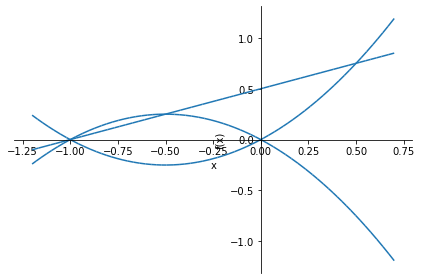

In [24]:
line_2 = -g
plot(line_1, l_c2, line_2, (x,-1.2, 0.7))

In [25]:
l_c=c*(x+1)
solve(line_1 - l_c,x)

[-1, -c]

In [26]:
solve(line_2 - l_c,x)

[-1, c]

また，$0<c<\fbox{ サ }$のとき，
線分PQと曲線$y=g(x)$で囲まれた図形の面積を$S$とし，
線分QRと曲線$y=g(x)$で囲まれた図形の面積を$T$とすると
$$
S=\frac{\fbox{ ソ }c^3 + \fbox{ タ }c^2 - \fbox{ チ }c +1}{\fbox{ ツ }}
$$
$$
T=c^\fbox{ テ }
$$
である．

In [27]:
expand(integrate(line_1 - l_c , (x, -1, -c)))

-c**3/6 + c**2/2 - c/2 + 1/6

In [28]:
integrate(l_c - line_1, (x, -c, 0))

c**3/3 - c**2*(c/2 + 1/2) + c**2

In [29]:
integrate(l_c - line_2, (x, 0, c))

-c**3/3 + c**2*(c/2 - 1/2) + c**2

In [30]:
expand(integrate(l_c - line_1, (x, -c, 0)) + integrate(l_c - line_2, (x, 0, c)))

c**2

# 問4 数値改変(20点)
問３において，
$g(x)=|x|(x+0.9)$とおき，
点P(-0.9, 0)として全ての問いに答えよ．
ただし，解答は整数とはならない場合がある．

In [31]:
from sympy import *

c, x = symbols('c x')
g=-x*(x+0.9)

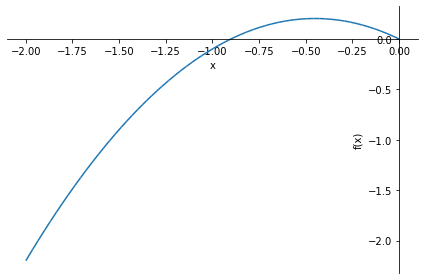

In [32]:
%matplotlib inline

line_1 = g
line_2 = -g
plot(line_1, (x,-2, 0), color='red')

In [33]:
diff(g,x)

-2*x - 0.9

In [34]:
m= diff(g,x).subs({x:-0.9})
m

0.900000000000000

In [35]:
l_c=m*(x+0.9)

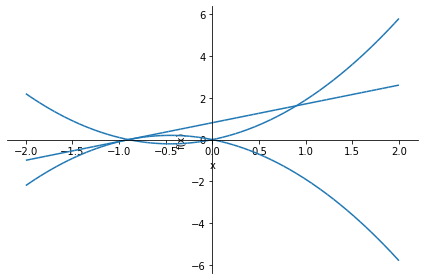

In [36]:
line_2 = -g
plot(line_1, l_c, line_2, (x,-2, 2))

In [37]:
l_c=c*(x+0.9)
solve(line_1 - l_c,x)

[-0.900000000000000, -c]

In [38]:
solve(line_2 - l_c,x)

[-0.900000000000000, c]

In [39]:
expand(integrate(line_1 - l_c , (x, -0.9, -c)))

-0.166666666666667*c**3 + 0.45*c**2 - 0.405*c + 0.1215

In [40]:
integrate(l_c - line_1, (x, -c, 0))

0.333333333333333*c**3 - c**2*(0.5*c + 0.45) + 0.9*c**2

In [41]:
integrate(l_c - line_2, (x, 0, c))

-0.333333333333333*c**3 + c**2*(0.5*c - 0.45) + 0.9*c**2

In [42]:
expand(integrate(l_c - line_1, (x, -c, 0)) + integrate(l_c - line_2, (x, 0, c)))

0.9*c**2